# FOMC Hawkish-Dovish Stance: Which AI System Should a Bond Desk Deploy?

**DS602 Lesson 5–6 mini-project.** We compare 3 AI systems on reading US Federal Reserve (FOMC) sentences and tagging each as **hawkish**, **dovish** or **neutral**.

| ID | System | Type |
|---|---|---|
| S1 | roberta-base (my fine-tune) | Fine-tuned specialist (runs in Colab) |
| S2 | Gemini Flash-Lite | General LLM, zero-shot (API) |
| S3 | Gemini Flash | General LLM, zero-shot (API) |
| B1 / B2 | Majority class / Random | Baselines (slide 10) |

**How to use this notebook**

1. Run top to bottom. Every model answer is **saved to disk** the first time, so re-running never pays twice.
2. Set `MOCK = True` in the Config cell to test the whole pipeline with fake data and fake models (free, 1 minute).
3. Sections marked ✍️ need your hand labels. The notebook exports a CSV, you fill it, then upload it back.

**Sections:** 0 Config · 1 Decision rule · 2 Data · 3 Hand-label sheets · 4 Systems · 5 Run · 6 Metrics · 7 Statistics · 8 Charts · 9 Business cost · 10 Calibration & cascade · 11 Randomness · 12 Noise ceiling · 13 Robustness · 14 Stance index · 15 Error analysis · 16 Recommendation

## 0. Setup and config
Install packages. Then set every choice in **one place**, so the run is reproducible (slide 39).

In [ ]:
# Colab only. Skip if packages are already installed.
!pip -q install -U google-genai datasets transformers statsmodels

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 60.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 45.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 94.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 262.5/262.5 kB 25.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.59.0 which is incompatible.


In [ ]:
# ---------------- CONFIG: every choice lives here ----------------
MOCK = False            # True = fake data + fake models, to test the pipeline for free
USE_DRIVE = True        # True = save results to Google Drive so they survive Colab resets
SEED = 42
RUN_DATE = "2026-09-30" # date you ran the models (write it on your slides)

# Gemini model IDs: CHECK these in the "list models" cell of section 4 before the full run
MODEL_S2 = "gemini-3.5-flash-lite"   # cheap general LLM
MODEL_S3 = "gemini-3.5-flash"        # stronger general LLM (same generation, bigger size)
ROBERTA_ID = "gtfintechlab/FOMC-RoBERTa"   # official model is gated (access pending); S1 is our own fine-tune

# Prices in USD per 1 million tokens, as of PRICE_DATE. Thinking tokens (if any) are billed as output.
PRICES = {
    MODEL_S2: {"in": 0.30, "out": 2.50},
    MODEL_S3: {"in": 1.50, "out": 9.00},
}
PRICE_DATE = "2026-09-30"

MAX_OUT_TOKENS = 20     # the label is 1 word; small cap keeps cost down
N_BOOT = 2000           # bootstrap resamples
N_RANDOMNESS_RUNS = 3   # Gemini repeats for Extra #4

# Business cost of each mistake (Extra #3). Rows = true, cols = predicted: dovish, hawkish, neutral.
FLIP_COST, MISS_COST = 5, 1
# Out-of-distribution dataset: another central bank from the same lab. VERIFY the exact name on Hugging Face.
OOD_DATASET, OOD_CONFIG = "gtfintechlab/european_central_bank", "5768"

In [ ]:
import os, re, time, json, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (f1_score, accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, cohen_kappa_score, classification_report)
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
warnings.filterwarnings("ignore")

random.seed(SEED); np.random.seed(SEED)
try:
    import torch; torch.manual_seed(SEED)
except ImportError:
    torch = None

try:
       import google.colab; IN_COLAB = True
except ImportError:
       IN_COLAB = False
if USE_DRIVE and IN_COLAB and not MOCK:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/fomc_eval"
else:
    BASE = "fomc_eval_mock" if MOCK else "fomc_eval"
CACHE, SHEETS, FIGS = f"{BASE}/cache", f"{BASE}/hand_labels", f"{BASE}/figures"
for d in (CACHE, SHEETS, FIGS):
    os.makedirs(d, exist_ok=True)

LABELS = ["dovish", "hawkish", "neutral"]          # dataset: 0 = dovish, 1 = hawkish, 2 = neutral
NAME2ID = {n: i for i, n in enumerate(LABELS)}
SYSTEMS = ["B1_majority", "B2_random", "S1_roberta", "S2_flash_lite", "S3_flash"]
MAIN = ["S1_roberta", "S2_flash_lite", "S3_flash"]
print("Saving everything under:", BASE)

Mounted at /content/drive
Saving everything under: /content/drive/MyDrive/fomc_eval


## 1. Decision rule — fixed BEFORE any results (Extra #10, slide 5)
Written first, so nobody can say we picked the winner after seeing scores.

In [ ]:
DECISION_RULE = f"""
Decision rule (fixed on {RUN_DATE}, before any results):
Deploy the CHEAPEST system (S1, S2, S3 or the S1->S3 cascade) that
  (a) has macro F1 within 2 points of the best system,
  (b) has p95 latency under 1 second per sentence, and
  (c) has a direction-flip rate not significantly worse than the best system
      (paired bootstrap 95% CI of the difference includes 0 or favours it).
If none qualifies, deploy the system with the highest macro F1.
"""
print(DECISION_RULE)


Decision rule (fixed on 2026-09-30, before any results):
Deploy the CHEAPEST system (S1, S2, S3 or the S1->S3 cascade) that
  (a) has macro F1 within 2 points of the best system,
  (b) has p95 latency under 1 second per sentence, and
  (c) has a direction-flip rate not significantly worse than the best system
      (paired bootstrap 95% CI of the difference includes 0 or favours it).
If none qualifies, deploy the system with the highest macro F1.



## 2. Data (slide 37)
**gtfintechlab/fomc_communication**: 2,480 human-labelled FOMC sentences (1,980 train, 496 test). We grade on the **test** split only. Train is used only for the majority baseline.

In [ ]:
MOCK_SENTENCES = [
    "Inflation remains elevated and further tightening may be appropriate.",
    "The Committee will keep supporting the economy until the recovery is complete.",
    "Equity prices fell over the intermeeting period.",
    "Risks of rising inflation call for a firmer policy stance.",
    "Weak labor markets argue for keeping rates low for longer.",
    "Survey measures of inflation expectations were little changed.",
    "If inflation does not moderate, higher rates will be needed.",
    "Participants saw no need to tighten policy in the near future.",
]

def load_fomc():
    if MOCK:
        rng = np.random.default_rng(SEED)
        def fake(n):
            s = [MOCK_SENTENCES[i % len(MOCK_SENTENCES)] + f" (item {i})" for i in range(n)]
            return pd.DataFrame({"sentence": s, "label": rng.choice(3, n, p=[.3, .25, .45]),
                                 "year": rng.integers(1996, 2023, n)})
        return fake(1980), fake(496)
    from datasets import load_dataset
    ds = load_dataset("gtfintechlab/fomc_communication")
    return ds["train"].to_pandas(), ds["test"].to_pandas()

train, test = load_fomc()
test = test.reset_index(drop=True)
test["id"] = [f"clean_{i}" for i in range(len(test))]      # stable id for every row
print(f"train={len(train)}  test={len(test)}")
print(test.label.map(dict(enumerate(LABELS))).value_counts().rename("test class counts"))
test.head(3)

README.md:   0%|          | 0.00/2.00k [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/423k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/104k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1984 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/496 [00:00<?, ? examples/s]

train=1984  test=496
label
neutral    247
dovish     135
hawkish    114
Name: test class counts, dtype: int64


,index,sentence,year,label,orig_index,id
0,659,Participants agreed that the labor market had ...,2004,2,625,clean_0
1,318,"You know, stimulating aggregate demand is one ...",2014,0,311,clean_1
2,584,Much of this performance was fueled by an inve...,2013,0,566,clean_2


**Data check worth saying in the talk:** the `year` column is unreliable (e.g. COVID-era sentences tagged with pre-2010 years). So we **never** split results by year. The cell below lets you show examples.

In [ ]:
mask = test.sentence.str.contains("COVID|pandemic|virus", case=False, regex=True)
print("Sentences mentioning COVID and the year the dataset gives them:")
print(test.loc[mask, ["year", "sentence"]].head(5).to_string())

Sentences mentioning COVID and the year the dataset gives them:
     year                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               

## 3. ✍️ Hand-label sheets — do these BEFORE looking at any model output
Three CSVs are exported to `hand_labels/`. Fill them in Google Sheets or Excel, save as CSV with the **same name**, and upload back to the same folder.

| File | What you do | Used by |
|---|---|---|
| `blind_50.csv` | Write `my_label` (dovish/hawkish/neutral) for 50 sentences. Gold is hidden on purpose. | Extra #7 noise ceiling, human rating |
| `negation_16.csv` | Rewrite each sentence with a negation in `new_sentence`; give its `new_label`. | Robustness: adversarial |
| `fresh_fomc.csv` | Paste ~40 sentences from recent FOMC statements; give `my_label`. | Extra #2 contamination check |

In [ ]:
def stratified_sample(df, n, seed):
    """n rows with every class represented in proportion."""
    frac = n / len(df)
    parts = [g.sample(min(len(g), max(1, round(len(g) * frac))), random_state=seed)
             for _, g in df.groupby("label")]
    return pd.concat(parts).sample(frac=1, random_state=seed).head(n)

def export_sheet(df, name):
    path = f"{SHEETS}/{name}"
    if os.path.exists(path):
        print(f"exists, not overwritten: {path}")
    else:
        df.to_csv(path, index=False); print(f"exported: {path}")

blind = stratified_sample(test, 50, SEED + 1)
export_sheet(blind[["id", "sentence"]].assign(my_label=""), "blind_50.csv")

adv_pool = stratified_sample(test[~test.id.isin(blind.id)], 50, SEED + 2)
neg_ids = adv_pool.id.iloc[:16]
export_sheet(adv_pool[adv_pool.id.isin(neg_ids)][["id", "sentence"]]
             .assign(new_sentence="", new_label=""), "negation_16.csv")

export_sheet(pd.DataFrame({"id": [f"fresh_{i}" for i in range(40)], "statement_date": "",
                           "sentence": "", "my_label": ""}), "fresh_fomc.csv")

exists, not overwritten: /content/drive/MyDrive/fomc_eval/hand_labels/blind_50.csv
exists, not overwritten: /content/drive/MyDrive/fomc_eval/hand_labels/negation_16.csv
exists, not overwritten: /content/drive/MyDrive/fomc_eval/hand_labels/fresh_fomc.csv


In [ ]:
def load_sheet(name, required):
    """Read a filled sheet back. Returns None if not filled yet."""
    path = f"{SHEETS}/{name}"
    if MOCK:  # fake filled sheets so the pipeline can be tested
        rng = np.random.default_rng(SEED)
        if name == "blind_50.csv":
            return blind.assign(my_label=np.where(rng.random(50) < .8, blind.label,
                                rng.choice(3, 50))).assign(my_label=lambda d: d.my_label.map(dict(enumerate(LABELS))))
        if name == "negation_16.csv":
            n = adv_pool[adv_pool.id.isin(neg_ids)]
            return n.assign(new_sentence="It is not true that " + n.sentence,
                            new_label=n.label.map({0: "hawkish", 1: "dovish", 2: "neutral"}))
        if name == "fresh_fomc.csv":
            return pd.DataFrame({"id": [f"fresh_{i}" for i in range(40)], "statement_date": "2026-07-29",
                                 "sentence": [MOCK_SENTENCES[i % 8] for i in range(40)],
                                 "my_label": [LABELS[i % 3] for i in range(40)]})
    if not os.path.exists(path):
        print(f"not found: {path}"); return None
    df = pd.read_csv(path)
    if df[required].isna().any().any() or (df[required].astype(str).apply(lambda c: c.str.strip()) == "").any().any():
        print(f"{name}: some rows still empty in {required} — fill them first"); return None
    return df

def to_id(x):
    return NAME2ID.get(str(x).strip().lower(), -1)

## 4. The systems
Every system is a function: **sentence in → label id, probabilities (if any), tokens used**. Latency is timed around the call.

In [ ]:
# ---------- Baselines (slide 10) ----------
MAJORITY = int(train.label.mode()[0])
_rng_b2 = np.random.default_rng(SEED)
def b1_majority(s): return {"pred": MAJORITY}
def b2_random(s):   return {"pred": int(_rng_b2.integers(0, 3))}
print("Majority class in train:", LABELS[MAJORITY])

Majority class in train: neutral


In [ ]:
# ---------- S1: our own fine-tuned RoBERTa specialist ----------
# FOMC-RoBERTa is gated (access pending), so we fine-tune roberta-base on the 1,984 TRAIN sentences only.
# Bonus: zero overlap with the 496 test sentences, so no leakage.
S1_BASE = "roberta-base"
S1_DIR = f"{BASE}/s1_roberta_finetuned"      # saved to Drive: trains once, reloads after that
EPOCHS, LR, BATCH, MAXLEN = 4, 2e-5, 16, 128

if MOCK:
    _rng_s1 = np.random.default_rng(SEED + 10)
    def s1_roberta(s):
        p = _rng_s1.dirichlet([2, 2, 2]); return {"pred": int(p.argmax()), "probs": p.tolist()}
else:
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
    from torch.utils.data import DataLoader, TensorDataset
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    print("S1 running on", dev)
    if os.path.exists(f"{S1_DIR}/config.json"):
        _tok = AutoTokenizer.from_pretrained(S1_DIR)
        _mdl = AutoModelForSequenceClassification.from_pretrained(S1_DIR).to(dev)
        print("Loaded saved S1 model from Drive (no retraining).")
    else:
        tr = train.sample(frac=1, random_state=SEED).reset_index(drop=True)
        n_val = int(0.1 * len(tr))
        val, trn = tr.iloc[:n_val].reset_index(drop=True), tr.iloc[n_val:].reset_index(drop=True)
        _tok = AutoTokenizer.from_pretrained(S1_BASE)
        _mdl = AutoModelForSequenceClassification.from_pretrained(
            S1_BASE, num_labels=3, id2label=dict(enumerate(LABELS)), label2id=NAME2ID).to(dev)
        def encode(df):
            e = _tok(list(df.sentence), truncation=True, max_length=MAXLEN, padding="max_length", return_tensors="pt")
            return TensorDataset(e["input_ids"], e["attention_mask"], torch.tensor(df.label.values))
        dl = DataLoader(encode(trn), batch_size=BATCH, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
        opt = torch.optim.AdamW(_mdl.parameters(), lr=LR, weight_decay=0.01)
        sch = get_linear_schedule_with_warmup(opt, int(0.1 * len(dl) * EPOCHS), len(dl) * EPOCHS)
        for ep in range(EPOCHS):
            _mdl.train(); total = 0.0
            for ids, am, lab in dl:
                ids, am, lab = ids.to(dev), am.to(dev), lab.to(dev)
                loss = _mdl(input_ids=ids, attention_mask=am, labels=lab).loss
                loss.backward(); torch.nn.utils.clip_grad_norm_(_mdl.parameters(), 1.0)
                opt.step(); sch.step(); opt.zero_grad(); total += loss.item()
            _mdl.eval(); vp = []
            with torch.no_grad():
                for i in range(0, len(val), 64):
                    e = _tok(list(val.sentence[i:i+64]), truncation=True, max_length=MAXLEN,
                             padding=True, return_tensors="pt").to(dev)
                    vp += _mdl(**e).logits.argmax(-1).tolist()
            print(f"epoch {ep+1}/{EPOCHS}: train loss {total/len(dl):.3f} | "
                  f"validation macro F1 {f1_score(val.label, vp, average='macro'):.3f}")
        _mdl.save_pretrained(S1_DIR); _tok.save_pretrained(S1_DIR)
        print("Saved fine-tuned model to", S1_DIR)
    _mdl.eval()
    def s1_roberta(s):
        e = _tok(s, truncation=True, max_length=MAXLEN, return_tensors="pt").to(dev)
        with torch.no_grad():
            p = torch.softmax(_mdl(**e).logits, -1)[0].cpu().numpy()
        return {"pred": int(p.argmax()), "probs": p.tolist()}

# Sanity check: the first sentence should lean hawkish.
for s in ["Such a directive would imply that any tightening should be implemented promptly if developments were perceived as pointing to rising inflation.",
          "The International Monetary Fund projects that global economic growth in 2019 will be the slowest since the financial crisis."]:
    r = s1_roberta(s); print(LABELS[r["pred"]], np.round(r["probs"], 3), "|", s[:60])

S1 running on cuda


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1/4: train loss 1.034 | validation macro F1 0.491
epoch 2/4: train loss 0.798 | validation macro F1 0.561
epoch 3/4: train loss 0.592 | validation macro F1 0.605
epoch 4/4: train loss 0.431 | validation macro F1 0.656


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved fine-tuned model to /content/drive/MyDrive/fomc_eval/s1_roberta_finetuned
hawkish [0.013 0.971 0.016] | Such a directive would imply that any tightening should be i
dovish [0.92  0.017 0.064] | The International Monetary Fund projects that global economi


In [ ]:
# ---------- S2 / S3: Gemini, zero-shot, same prompt ----------
PROMPT = """Classify the monetary policy stance of this FOMC sentence.
hawkish = leans toward tighter policy or higher rates (e.g. inflation concerns).
dovish = leans toward easier policy or lower rates (e.g. weak growth, jobs support).
neutral = neither, or purely descriptive.
Answer with exactly one word: hawkish, dovish or neutral.

Sentence: {s}"""

def parse(reply):
    """Layer 0 deterministic check (slide 25): valid label or -1 (parse failure)."""
    if reply is None: return -1
    w = str(reply).strip().lower().strip(".!\"'*` \n")
    return NAME2ID.get(w, -1)

if MOCK:
    _rng_g = np.random.default_rng(SEED + 20)
    def gemini_raw(model, text, max_out=MAX_OUT_TOKENS):
        time.sleep(0.001)
        return {"text": LABELS[int(_rng_g.integers(0, 3))] if _rng_g.random() > .02 else "I think hawkish",
                "in_tok": 90, "out_tok": 1, "think_tok": 0}
else:
    from google import genai
    from google.genai import types
    try:
        from google.colab import userdata
        _key = userdata.get("GEMINI_API_KEY")     # Colab: key icon on the left -> add GEMINI_API_KEY
    except Exception:
        _key = os.environ.get("GEMINI_API_KEY")
    client = genai.Client(api_key=_key)
    _no_thinking_ok = {}
    def gemini_raw(model, text, max_out=MAX_OUT_TOKENS):
        """One API call. Turns thinking off where the model allows it (cheaper, and
        thinking tokens would otherwise eat the tiny output budget)."""
        base = dict(temperature=0, max_output_tokens=max_out)
        if _no_thinking_ok.get(model, True):
            try:
                cfg = types.GenerateContentConfig(**base, thinking_config=types.ThinkingConfig(thinking_budget=0))
                resp = client.models.generate_content(model=model, contents=text, config=cfg)
                _no_thinking_ok[model] = True
            except Exception as e:
                if "thinking" not in str(e).lower(): raise
                _no_thinking_ok[model] = False
                return gemini_raw(model, text, max_out)
        else:
            resp = client.models.generate_content(model=model, contents=text,
                                                  config=types.GenerateContentConfig(**base))
        u = resp.usage_metadata
        return {"text": resp.text, "in_tok": getattr(u, "prompt_token_count", 0) or 0,
                "out_tok": getattr(u, "candidates_token_count", 0) or 0,
                "think_tok": getattr(u, "thoughts_token_count", 0) or 0}

def gemini_call(model, sentence, retries=4):
    """Retry on errors (rate limits etc.). Never silently drops a sentence."""
    for a in range(retries):
        try:
            r = gemini_raw(model, PROMPT.format(s=sentence))
            return {"pred": parse(r["text"]), "raw": r["text"], "in_tok": r["in_tok"],
                    "out_tok": r["out_tok"] + r["think_tok"], "api_error": False}
        except Exception as e:
            wait = 2 ** a * 2
            print(f"  retry {a+1} in {wait}s: {str(e)[:80]}"); time.sleep(wait)
    return {"pred": -1, "raw": "API_ERROR", "in_tok": 0, "out_tok": 0, "api_error": True}

def s2_flash_lite(s): return gemini_call(MODEL_S2, s)
def s3_flash(s):      return gemini_call(MODEL_S3, s)

FUNCS = {"B1_majority": b1_majority, "B2_random": b2_random, "S1_roberta": s1_roberta,
         "S2_flash_lite": s2_flash_lite, "S3_flash": s3_flash}

In [ ]:
# List available Gemini models, to verify MODEL_S2 / MODEL_S3 exist for your key.
if not MOCK:
    names = [m.name for m in client.models.list() if "gemini" in m.name]
    print("\n".join(n for n in names if "flash" in n))

models/gemini-2.5-flash
models/gemini-2.5-flash-preview-tts
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-3.1-flash-tts-preview
models/gemini-3.8-flash-tts
models/gemini-3.8-flash-lite-tts
models/gemini-2.5-flash-native-audio-latest
models/gemini-2.5-flash-native-audio-preview-09-2025
models/gemini-2.5-flash-native-audio-preview-12-2025
models/gemini-3.1-flash-live-preview


## 5. Run every system on every sentence (slide 39: "on ALL test examples")
`run_system` saves answers every 25 sentences. If Colab stops, re-run the cell: it **resumes** where it left off and never pays twice.

In [ ]:
def run_system(sys_name, df, set_name, run=1, verbose=True):
    path = f"{CACHE}/{set_name}__{sys_name}__run{run}.csv"
    done = pd.read_csv(path) if os.path.exists(path) else pd.DataFrame()
    done_ids = set(done.id) if len(done) else set()
    todo = df[~df.id.isin(done_ids)]
    rows, fn = [], FUNCS[sys_name]
    for k, (_, r) in enumerate(todo.iterrows()):
        t0 = time.perf_counter(); out = fn(r.sentence); lat = time.perf_counter() - t0
        out = dict(out); probs = out.pop("probs", None)
        rows.append({"id": r.id, **out, "latency_s": lat,
                     "probs": json.dumps(probs) if probs is not None else ""})
        if len(rows) % 25 == 0 or k == len(todo) - 1:
            done = pd.concat([done, pd.DataFrame(rows)], ignore_index=True); rows = []
            done.to_csv(path, index=False)
    if verbose:
        print(f"{set_name:>14} | {sys_name:<14} run{run}: {len(done)} rows ({len(todo)} new)")
    res = df[["id"]].merge(done, on="id", how="left")
    for c, v in [("in_tok", 0), ("out_tok", 0), ("api_error", False), ("raw", "")]:
        if c not in res: res[c] = v
    res["in_tok"] = res["in_tok"].fillna(0); res["out_tok"] = res["out_tok"].fillna(0)
    return res

# Smoke test: 10 sentences each for Gemini before the full run. Check parse failures + token counts.
smoke = test.head(10)
for s in ["S2_flash_lite", "S3_flash"]:
    r = run_system(s, smoke, "smoke")
    print(r[["raw", "pred", "in_tok", "out_tok", "latency_s"]].head(3).to_string(), "\n")

gemini-3.5-flash-lite: thinking cannot be turned off -> using default thinking, larger budget
         smoke | S2_flash_lite  run1: 10 rows (10 new)
       raw  pred  in_tok  out_tok  latency_s
0  neutral     2     107        1   1.171754
1  neutral     2     117        1   0.675475
2  Neutral     2     103        1   0.759223 

         smoke | S3_flash       run1: 10 rows (0 new)
       raw  pred  in_tok  out_tok  latency_s
0  neutral     2     107        1   1.628933
1  neutral     2     117        1   1.164754
2  neutral     2     103        1   1.283541 



In [ ]:
# Fix: Flash-Lite rejects "thinking off". Fall back to default thinking with a bigger output budget.
import glob
def gemini_raw(model, text, max_out=MAX_OUT_TOKENS):
    if _no_thinking_ok.get(model, True):
        try:
            cfg = types.GenerateContentConfig(temperature=0, max_output_tokens=max_out,
                      thinking_config=types.ThinkingConfig(thinking_budget=0))
            resp = client.models.generate_content(model=model, contents=text, config=cfg)
            _no_thinking_ok[model] = True
        except Exception as e:
            if "INVALID_ARGUMENT" not in str(e) and "thinking" not in str(e).lower():
                raise
            _no_thinking_ok[model] = False
            print(f"{model}: thinking cannot be turned off -> using default thinking, larger budget")
            return gemini_raw(model, text, max_out)
    else:
        cfg = types.GenerateContentConfig(temperature=0, max_output_tokens=max(max_out, 1024))
        resp = client.models.generate_content(model=model, contents=text, config=cfg)
    u = resp.usage_metadata
    return {"text": resp.text, "in_tok": getattr(u, "prompt_token_count", 0) or 0,
            "out_tok": getattr(u, "candidates_token_count", 0) or 0,
            "think_tok": getattr(u, "thoughts_token_count", 0) or 0}

# Delete the saved failed S2 answers so they get redone
for f in glob.glob(f"{CACHE}/*S2_flash_lite*.csv"):
    os.remove(f); print("deleted", f)

deleted /content/drive/MyDrive/fomc_eval/cache/smoke__S2_flash_lite__run1.csv


In [ ]:
# Estimate the bill before the full run (fill PRICES first).
def cost_usd(model, in_tok, out_tok):
    p = PRICES.get(model, {"in": 0, "out": 0})
    return in_tok / 1e6 * p["in"] + out_tok / 1e6 * p["out"]

if not MOCK and all(v["in"] == 0 and v["out"] == 0 for v in PRICES.values()):
    print("WARNING: PRICES are still 0. Fill them in the Config cell, or every cost number will be 0.")
for s, m in [("S2_flash_lite", MODEL_S2), ("S3_flash", MODEL_S3)]:
    r = run_system(s, smoke, "smoke", verbose=False)
    per = cost_usd(m, r.in_tok.mean(), r.out_tok.mean())
    print(f"{s}: ~${per*1000:.4f} per 1,000 sentences -> clean set x {N_RANDOMNESS_RUNS} runs "
          f"~${per*len(test)*N_RANDOMNESS_RUNS:.3f}")

S2_flash_lite: ~$0.0373 per 1,000 sentences -> clean set x 3 runs ~$0.056
S3_flash: ~$0.1827 per 1,000 sentences -> clean set x 3 runs ~$0.272


In [ ]:
# FULL RUN on the clean test set (run 1 = the main run).
RES = {s: run_system(s, test, "clean") for s in SYSTEMS}
y = test.label.values

         clean | B1_majority    run1: 496 rows (496 new)
         clean | B2_random      run1: 496 rows (496 new)
         clean | S1_roberta     run1: 496 rows (496 new)
         clean | S2_flash_lite  run1: 496 rows (496 new)
         clean | S3_flash       run1: 496 rows (496 new)


## 6. Metrics (slide 36: quality REQUIRED + cost REQUIRED)
One function computes everything for one system. Parse failures and API errors count as **wrong**.

In [ ]:
MODEL_OF = {"S2_flash_lite": MODEL_S2, "S3_flash": MODEL_S3}
COST = np.array([[0, FLIP_COST, MISS_COST], [FLIP_COST, 0, MISS_COST], [MISS_COST, MISS_COST, 0]])

def flip_mask(y, p):  return ((y == 0) & (p == 1)) | ((y == 1) & (p == 0))

def business_cost(y, p, cost=COST, fail_cost=MISS_COST):
    """Expected cost per 1,000 sentences. Parse failure = a missed signal."""
    c = np.where(p < 0, fail_cost, cost[y, np.clip(p, 0, 2)])
    return c.mean() * 1000

def summarise(name, y, res):
    p = res.pred.fillna(-1).astype(int).values
    lat = res.latency_s.values
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, labels=[0, 1, 2], zero_division=0)
    usd = cost_usd(MODEL_OF[name], res.in_tok.sum(), res.out_tok.sum()) if name in MODEL_OF else 0.0
    return {
        "system": name,
        "macro_f1": f1_score(y, p, labels=[0, 1, 2], average="macro", zero_division=0),
        "weighted_f1": f1_score(y, p, labels=[0, 1, 2], average="weighted", zero_division=0),
        "accuracy": accuracy_score(y, p),
        "hawk_precision": pr[1], "hawk_recall": rc[1], "dove_precision": pr[0], "dove_recall": rc[0],
        "flip_rate": flip_mask(y, p).mean(),
        "parse_fail_rate": ((p == -1) & ~res.api_error.astype(bool)).mean(),
        "api_error_rate": res.api_error.astype(bool).mean(),
        "p50_s": np.percentile(lat, 50), "p95_s": np.percentile(lat, 95), "p99_s": np.percentile(lat, 99),
        "throughput_per_s": len(lat) / lat.sum() if lat.sum() > 0 else np.inf,
        "tokens_per_req": (res.in_tok + res.out_tok).mean(),
        "usd_per_req": usd / len(p), "usd_per_1000": usd / len(p) * 1000,
        "biz_cost_per_1000": business_cost(y, p),
    }

TABLE = pd.DataFrame([summarise(s, y, RES[s]) for s in SYSTEMS]).set_index("system")
TABLE.round(4)

,macro_f1,weighted_f1,accuracy,hawk_precision,hawk_recall,dove_precision,dove_recall,flip_rate,parse_fail_rate,api_error_rate,p50_s,p95_s,p99_s,throughput_per_s,tokens_per_req,usd_per_req,usd_per_1000,biz_cost_per_1000
system,,,,,,,,,,,,,,,,,,
B1_majority,0.2216,0.3311,0.4980,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0,0.0000,0.0000,0.0000,89039.6020,0.0000,0.0000,0.0000,502.0161
B2_random,0.3146,0.3424,0.3286,0.2160,0.3070,0.2381,0.2963,0.1935,0.0,0.0,0.0000,0.0000,0.0001,52350.4453,0.0000,0.0000,0.0000,1445.5645
S1_roberta,0.6604,0.6803,0.6794,0.5820,0.6228,0.6466,0.6370,0.0625,0.0,0.0,0.0090,0.0116,0.0158,105.8750,0.0000,0.0000,0.0000,570.5645
S2_flash_lite,0.5946,0.6275,0.6452,0.7167,0.3772,0.6634,0.4963,0.0282,0.0,0.0,0.7621,0.9611,1.1519,1.3213,118.7782,0.0000,0.0390,467.7419
S3_flash,0.6215,0.6438,0.6512,0.7183,0.4474,0.6202,0.5926,0.0282,0.0,0.0,1.2834,1.9751,2.8391,0.7174,118.9133,0.0002,0.1908,461.6935


In [ ]:
# Per-class detail for the 3 main systems
for s in MAIN:
    p = RES[s].pred.fillna(-1).astype(int).values
    print(f"===== {s} =====")
    print(classification_report(y, p, labels=[0, 1, 2], target_names=LABELS, zero_division=0))

===== S1_roberta =====
              precision    recall  f1-score   support

      dovish       0.65      0.64      0.64       135
     hawkish       0.58      0.62      0.60       114
     neutral       0.75      0.73      0.74       247

    accuracy                           0.68       496
   macro avg       0.66      0.66      0.66       496
weighted avg       0.68      0.68      0.68       496

===== S2_flash_lite =====
              precision    recall  f1-score   support

      dovish       0.66      0.50      0.57       135
     hawkish       0.72      0.38      0.49       114
     neutral       0.63      0.85      0.72       247

    accuracy                           0.65       496
   macro avg       0.67      0.57      0.59       496
weighted avg       0.66      0.65      0.63       496

===== S3_flash =====
              precision    recall  f1-score   support

      dovish       0.62      0.59      0.61       135
     hawkish       0.72      0.45      0.55       114
     

**Fairness note for the cost slide (small touch):** S1 runs locally in Colab; S2/S3 go over the internet. Latency is therefore not like-for-like. S1's dollar cost is shown as 0 (compute only).

## 7. Statistics (step 5: confidence intervals; slide 39: statistical rigour)
- **Bootstrap 95% CI** for each system's macro F1.
- **Paired bootstrap** for differences (same sentences for both systems).
- **McNemar** test for each pair, then **Holm** correction for 3 comparisons (Extra #9).

In [ ]:
_rng_boot = np.random.default_rng(SEED)
BOOT_IDX = _rng_boot.integers(0, len(y), size=(N_BOOT, len(y)))   # same resamples for every system = paired

def macro_f1(yy, pp): return f1_score(yy, pp, labels=[0, 1, 2], average="macro", zero_division=0)

def boot_scores(p, metric=macro_f1):
    return np.array([metric(y[i], p[i]) for i in BOOT_IDX])

PRED = {s: RES[s].pred.fillna(-1).astype(int).values for s in SYSTEMS}
BOOT = {s: boot_scores(PRED[s]) for s in SYSTEMS}
TABLE["f1_ci_low"] = [np.percentile(BOOT[s], 2.5) for s in TABLE.index]
TABLE["f1_ci_high"] = [np.percentile(BOOT[s], 97.5) for s in TABLE.index]
TABLE[["macro_f1", "f1_ci_low", "f1_ci_high"]].round(3)

,macro_f1,f1_ci_low,f1_ci_high
system,,,
B1_majority,0.222,0.207,0.234
B2_random,0.315,0.275,0.356
S1_roberta,0.660,0.616,0.703
S2_flash_lite,0.595,0.545,0.643
S3_flash,0.622,0.573,0.668


In [ ]:
def mcnemar_p(pa, pb):
    a, b = pa == y, pb == y
    t = [[(a & b).sum(), (a & ~b).sum()], [(~a & b).sum(), (~a & ~b).sum()]]
    exact = min(t[0][1], t[1][0]) < 25
    return mcnemar(t, exact=exact, correction=not exact).pvalue, t[0][1], t[1][0]

pairs = [("S1_roberta", "S2_flash_lite"), ("S1_roberta", "S3_flash"), ("S2_flash_lite", "S3_flash")]
rows = []
for a, b in pairs:
    d = BOOT[a] - BOOT[b]
    p, a_only, b_only = mcnemar_p(PRED[a], PRED[b])
    rows.append({"pair": f"{a} vs {b}", "F1 diff": TABLE.macro_f1[a] - TABLE.macro_f1[b],
                 "diff CI low": np.percentile(d, 2.5), "diff CI high": np.percentile(d, 97.5),
                 f"only A right": a_only, f"only B right": b_only, "McNemar p": p})
PAIRS = pd.DataFrame(rows)
rej, p_holm, _, _ = multipletests(PAIRS["McNemar p"], alpha=0.05, method="holm")
PAIRS["Holm p"], PAIRS["significant"] = p_holm, rej
PAIRS.round(4)

,pair,F1 diff,diff CI low,diff CI high,only A right,only B right,McNemar p,Holm p,significant
0,S1_roberta vs S2_flash_lite,0.0658,0.0094,0.1234,86,69,0.1987,0.5962,False
1,S1_roberta vs S3_flash,0.0389,-0.0118,0.0911,75,61,0.2650,0.5962,False
2,S2_flash_lite vs S3_flash,-0.0270,-0.0617,0.0087,26,29,0.7874,0.7874,False


**Reading the results**
- No pair is significant after Holm correction (all Holm p ≥ 0.59).
- McNemar tests accuracy. The paired bootstrap tests macro F1. They can disagree.
- S1 vs S2: macro F1 CI excludes 0 (+0.009 to +0.123), but McNemar is not significant. S1's edge comes from balanced recall across classes, not more correct sentences overall.
- S1 vs S3 and S2 vs S3: CIs include 0. No evidence of a difference.
- Our pre-registered rule uses point estimates, not significance tests. S1 has the best macro F1 (0.660). S2 (−6.5 pts) and S3 (−3.8 pts) are not within 2 points. The final choice is made in the last section, after the cascade and latency checks.
- Caveat: S1 vs S3 is not significant (CI −0.012 to +0.091). The ranking could change on new data.

## 8. Charts (slide 41: at least 1 chart REQUIRED)

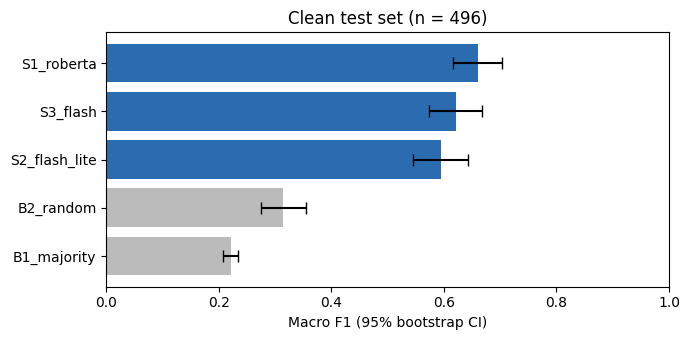

In [ ]:
def savefig(name):
    plt.tight_layout(); plt.savefig(f"{FIGS}/{name}.png", dpi=200, bbox_inches="tight"); plt.show()

# Chart 1: macro F1 with 95% CI (the required comparison chart)
t = TABLE.sort_values("macro_f1")
fig, ax = plt.subplots(figsize=(7, 3.5))
err = [t.macro_f1 - t.f1_ci_low, t.f1_ci_high - t.macro_f1]
colors = ["#bbbbbb" if s.startswith("B") else "#2b6cb0" for s in t.index]
ax.barh(t.index, t.macro_f1, xerr=err, color=colors, capsize=4)
ax.set_xlabel("Macro F1 (95% bootstrap CI)"); ax.set_xlim(0, 1)
ax.set_title("Clean test set (n = %d)" % len(y))
savefig("01_macro_f1_ci")

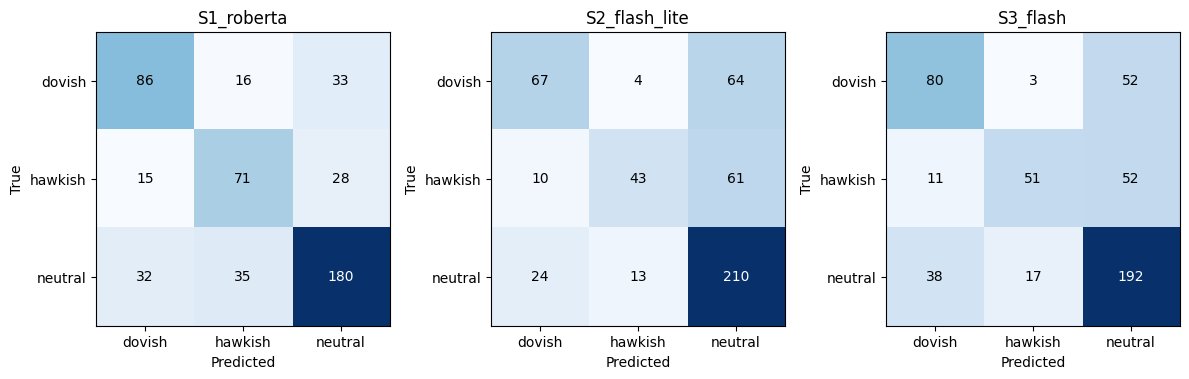

In [ ]:
# Chart 2: confusion matrices, main systems
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, s in zip(axes, MAIN):
    cm = confusion_matrix(y, PRED[s], labels=[0, 1, 2])
    ax.imshow(cm, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(3), LABELS); ax.set_yticks(range(3), LABELS)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(s)
savefig("02_confusion_matrices")

## 9. Business cost matrix (Extra #3, slide 12)
A hawkish ↔ dovish **flip** can mean a wrong-way trade (cost 5). A missed or false signal costs 1. These weights are **assumptions**, so we check the ranking at flip costs 3, 5 and 10.

In [ ]:
sens = {}
for fc in [3, 5, 10]:
    c = np.array([[0, fc, 1], [fc, 0, 1], [1, 1, 0]])
    sens[f"flip cost {fc}"] = {s: business_cost(y, PRED[s], c) for s in SYSTEMS}
SENS = pd.DataFrame(sens).round(1)
print("Expected business cost per 1,000 sentences (lower is better)")
SENS.assign(rank_at_5=SENS["flip cost 5"].rank().astype(int))

Expected business cost per 1,000 sentences (lower is better)


,flip cost 3,flip cost 5,flip cost 10,rank_at_5
B1_majority,502.0,502.0,502.0,3
B2_random,1058.5,1445.6,2413.3,5
S1_roberta,445.6,570.6,883.1,4
S2_flash_lite,411.3,467.7,608.9,2
S3_flash,405.2,461.7,602.8,1


## 10. Calibration of RoBERTa + the S1 → S3 cascade (Extra #6, slide 25)
**Calibration:** when RoBERTa is 90% sure, is it right 90% of the time?
**Cascade:** trust RoBERTa when it is confident; send only the unsure sentences to Gemini Flash. Uses answers we already have, so it costs nothing extra to evaluate.

ECE (expected calibration error) = 0.141  (0 = perfectly calibrated)


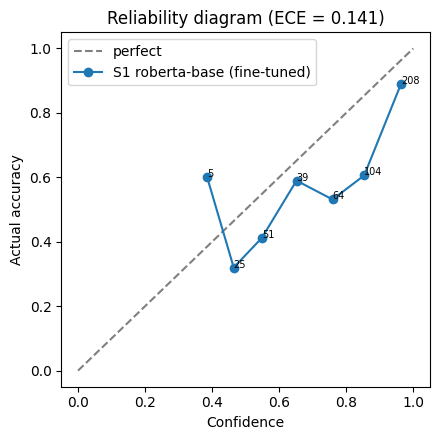

In [ ]:
probs = np.array([json.loads(x) for x in RES["S1_roberta"].probs])
conf, correct = probs.max(1), probs.argmax(1) == y
edges = np.linspace(0, 1, 11); b = np.clip(np.digitize(conf, edges) - 1, 0, 9)
rel = pd.DataFrame({"bin": b, "conf": conf, "correct": correct}).groupby("bin").agg(
    n=("conf", "size"), avg_conf=("conf", "mean"), accuracy=("correct", "mean"))
ECE = (rel.n / rel.n.sum() * (rel.avg_conf - rel.accuracy).abs()).sum()
print(f"ECE (expected calibration error) = {ECE:.3f}  (0 = perfectly calibrated)")

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect")
ax.plot(rel.avg_conf, rel.accuracy, "o-", label="S1 roberta-base (fine-tuned)")
for _, r in rel.iterrows(): ax.annotate(int(r.n), (r.avg_conf, r.accuracy), fontsize=7)
ax.set_xlabel("Confidence"); ax.set_ylabel("Actual accuracy"); ax.legend()
ax.set_title(f"Reliability diagram (ECE = {ECE:.3f})")
savefig("03_reliability_roberta")

In [ ]:
s3 = RES["S3_flash"]
s3_cost_each = cost_usd(MODEL_S3, s3.in_tok, s3.out_tok).values
casc = []
for th in [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]:
    esc = conf < th
    p = np.where(esc, PRED["S3_flash"], PRED["S1_roberta"])
    lat = RES["S1_roberta"].latency_s.values + np.where(esc, s3.latency_s.values, 0)
    casc.append({"threshold": th, "escalated_share": esc.mean(), "macro_f1": macro_f1(y, p),
                 "flip_rate": flip_mask(y, p).mean(), "p95_s": np.percentile(lat, 95),
                 "usd_per_1000": s3_cost_each[esc].sum() / len(y) * 1000,
                 "biz_cost_per_1000": business_cost(y, p), "pred": p, "lat": lat})
CASC = pd.DataFrame(casc)
CASC.drop(columns=["pred", "lat"]).round(4)

,threshold,escalated_share,macro_f1,flip_rate,p95_s,usd_per_1000,biz_cost_per_1000
0,0.50,0.0605,0.6680,0.0565,1.1872,0.0112,540.3226
1,0.60,0.1633,0.6701,0.0403,1.3828,0.0304,471.7742
2,0.70,0.2419,0.6728,0.0383,1.4642,0.0453,457.6613
3,0.80,0.3710,0.6649,0.0262,1.6225,0.0701,419.3548
4,0.90,0.5806,0.6759,0.0282,1.7406,0.1114,415.3226
5,0.95,0.6976,0.6332,0.0282,1.8583,0.1340,449.5968


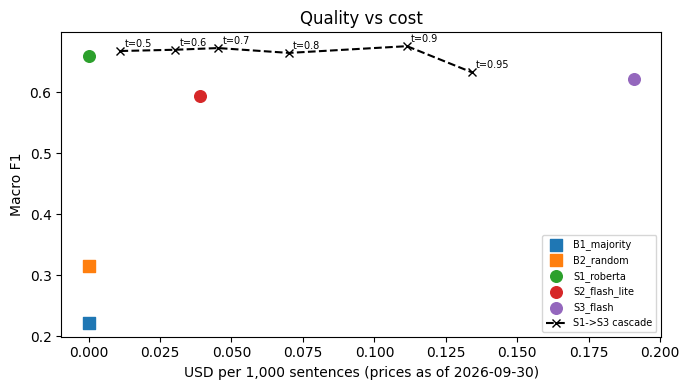

In [ ]:
# Chart 3: quality vs cost Pareto view (slide 32), with cascade points
fig, ax = plt.subplots(figsize=(7, 4))
for s in SYSTEMS:
    ax.scatter(TABLE.usd_per_1000[s], TABLE.macro_f1[s], s=70, label=s,
               marker="s" if s.startswith("B") else "o")
ax.plot(CASC.usd_per_1000, CASC.macro_f1, "x--", color="black", label="S1->S3 cascade")
for _, r in CASC.iterrows():
    ax.annotate(f"t={r.threshold}", (r.usd_per_1000, r.macro_f1), fontsize=7, xytext=(3, 3),
                textcoords="offset points")
ax.set_xlabel(f"USD per 1,000 sentences (prices as of {PRICE_DATE})"); ax.set_ylabel("Macro F1")
ax.legend(fontsize=7, loc="lower right"); ax.set_title("Quality vs cost")
savefig("04_pareto_quality_cost")

## 11. LLM randomness (Extra #4 — agenda: "stochastic, opaque policy")
Even at temperature 0, answers can change between runs. We run S2 and S3 two more times. RoBERTa is deterministic, a useful contrast.

In [ ]:
RAND = []
for s in ["S2_flash_lite", "S3_flash"]:
    runs = [RES[s]] + [run_system(s, test, "clean", run=r) for r in range(2, N_RANDOMNESS_RUNS + 1)]
    P = np.stack([r.pred.fillna(-1).astype(int).values for r in runs])
    f1s = [macro_f1(y, p) for p in P]
    RAND.append({"system": s, "runs": len(runs), "all_runs_agree": (P == P[0]).all(0).mean(),
                 "macro_f1_min": min(f1s), "macro_f1_max": max(f1s), "macro_f1_sd": np.std(f1s)})
    unstable = test.sentence[~(P == P[0]).all(0)].head(3).tolist()
    print(s, "example unstable sentences:", *[u[:90] for u in unstable], sep="\n  ")
pd.DataFrame(RAND).round(4)

         clean | S2_flash_lite  run2: 496 rows (496 new)
         clean | S2_flash_lite  run3: 496 rows (496 new)
S2_flash_lite
  example unstable sentences:
  There are, however, some problems with this story as the principal explanation for the fav
  However, with monetary policy assumed to remain highly accommodative, the staff continued 
  Some have been concerned that the Federal Reserve and the Treasury might be working at cro
         clean | S3_flash       run2: 496 rows (496 new)
         clean | S3_flash       run3: 496 rows (496 new)
S3_flash
  example unstable sentences:


,system,runs,all_runs_agree,macro_f1_min,macro_f1_max,macro_f1_sd
0,S2_flash_lite,3,0.9395,0.5747,0.5946,0.0081
1,S3_flash,3,1.0000,0.6215,0.6215,0.0000


## 12. ✍️ Label-noise ceiling + human rating (Extra #7, slide 37)
Your 50 blind labels vs the dataset's gold labels. If even two humans disagree often, no model can score near 100%.

In [ ]:
bl = load_sheet("blind_50.csv", ["my_label"])
if bl is not None:
    bl = bl[["id", "my_label"]].merge(test[["id", "label"]], on="id")
    mine, gold = bl.my_label.map(to_id).values, bl.label.values
    kappa, agree = cohen_kappa_score(mine, gold), (mine == gold).mean()
    band = "strong" if kappa > .8 else "substantial" if kappa > .6 else "moderate" if kappa > .4 else "weak"
    print(f"You vs gold: agreement = {agree:.0%}, Cohen's kappa = {kappa:.2f} ({band})")
    idx = test.index[test.id.isin(bl.id)]
    for s in MAIN:
        p = PRED[s][idx]; g = y[idx]; m = pd.Series(mine, index=bl.id).loc[test.id[idx]].values
        print(f"  {s:<14} agrees with gold {np.mean(p == g):.0%} | with you {np.mean(p == m):.0%}")
    DISPUTED = bl[mine != gold].merge(test[["id", "sentence"]], on="id")
    print("\nSentences where you and gold disagree (candidates for 'gold disputable'):")
    print(DISPUTED[["sentence", "label", "my_label"]].head(8).to_string())

You vs gold: agreement = 58%, Cohen's kappa = 0.31 (weak)
  S1_roberta     agrees with gold 70% | with you 66%
  S2_flash_lite  agrees with gold 60% | with you 76%
  S3_flash       agrees with gold 56% | with you 78%

Sentences where you and gold disagree (candidates for 'gold disputable'):
                                                                                                                                                                                                                                                                                                                                                                                                                                                                              sentence  label my_label
0                                                                                                                                                                                                                            

## 13. Robustness matrix (slide 36 OPTIONAL — all 4 items covered)
| Set | Tests | Built how |
|---|---|---|
| short / long | long-context | shortest and longest 20% of clean (no new calls) |
| adversarial | typos, hedging (auto) + negation (your sheet) | 50 sentences |
| multilingual | Chinese + Hindi | 50 sentences translated by Gemini Flash |
| ood | another central bank | 100 sentences |
| fresh | contamination (Extra #2) | your ~40 recent FOMC sentences |

In [36]:
def typo(s, seed):
    r = random.Random(seed); w = s.split()
    long_idx = [i for i, x in enumerate(w) if len(x) > 4]
    for i in r.sample(long_idx, min(2, len(long_idx))):
        j = r.randrange(1, len(w[i]) - 2); x = list(w[i]); x[j], x[j+1] = x[j+1], x[j]; w[i] = "".join(x)
    return " ".join(w)

def hedge(s):  return "Some participants noted that " + s[0].lower() + s[1:]

auto = adv_pool[~adv_pool.id.isin(neg_ids)].reset_index(drop=True)
adv = pd.concat([
    auto.iloc[:17].assign(sentence=[typo(s, i) for i, s in enumerate(auto.sentence[:17])], kind="typo"),
    auto.iloc[17:].assign(sentence=auto.sentence[17:].map(hedge), kind="hedge"),
])[["id", "sentence", "label", "kind"]]
neg = load_sheet("negation_16.csv", ["new_sentence", "new_label"])
if neg is not None:
    adv = pd.concat([adv, pd.DataFrame({"id": neg.id, "sentence": neg.new_sentence,
                                        "label": neg.new_label.map(to_id), "kind": "negation"})])
adv["id"] = adv.id + "_" + adv.kind
print(adv.kind.value_counts().to_dict())
adv.head(3)

{'typo': 17, 'hedge': 17, 'negation': 16}


,id,sentence,label,kind
0,clean_335_typo,Overall inflation was projected to remain subd...,0,typo
1,clean_458_typo,"With inventories lower, firms were beginning t...",2,typo
2,clean_366_typo,"Not surprisingly, the projected path of above-...",1,typo


In [37]:
# Multilingual: translate 50 sentences (cached). Note: same model family translates and classifies
# for S3 -> possible self-preference (slide 25 "model-family nepotism"). Say it on the slide.
TRANSLATE = "Translate this sentence into {lang}. Output only the translation.\n\n{s}"
ml_src = stratified_sample(test[~test.id.isin(blind.id) & ~test.id.isin(adv_pool.id)], 50, SEED + 3)
ml_rows = []
tpath = f"{CACHE}/translations.csv"
tcache = pd.read_csv(tpath) if os.path.exists(tpath) else pd.DataFrame(columns=["id", "sentence"])
for lang, code_ in [("Simplified Chinese", "zh"), ("Hindi", "hi")]:
    for _, r in ml_src.iterrows():
        tid = f"{r.id}_{code_}"
        hit = tcache[tcache.id == tid]
        if len(hit): txt = hit.sentence.iloc[0]
        elif MOCK:  txt = f"[{code_}] {r.sentence}"
        else:
            txt = gemini_raw(MODEL_S3, TRANSLATE.format(lang=lang, s=r.sentence), max_out=400)["text"].strip()
            tcache = pd.concat([tcache, pd.DataFrame([{"id": tid, "sentence": txt}])]); tcache.to_csv(tpath, index=False)
        ml_rows.append({"id": tid, "sentence": txt, "label": r.label, "lang": code_})
ml = pd.DataFrame(ml_rows)
print(ml.groupby("lang").size().to_dict()); ml.sample(2, random_state=SEED)

{'hi': 50, 'zh': 50}


,id,sentence,label,lang
83,clean_327_hi,"फिशर, सहाय और वेघ (2002) उच्च-मुद्रास्फीति वाल...",2,hi
53,clean_214_hi,"इसके अतिरिक्त, विदेशों में प्रतिफल की अनुमानित...",0,hi


In [40]:
# Out-of-distribution: another central bank (same lab). Their stance labels differ:
# LABEL_0 neutral, LABEL_1 hawkish, LABEL_2 dovish, LABEL_3 irrelevant -> we map BY NAME and drop irrelevant.
def load_ood(n=100):
    if MOCK:
        return test.sample(n, random_state=SEED + 4).assign(id=lambda d: "ood_" + d.id)[["id", "sentence", "label"]]
    try:
        from datasets import load_dataset
        d = load_dataset(OOD_DATASET, OOD_CONFIG)
        df = d["test"].to_pandas() if "test" in d else d[list(d.keys())[0]].to_pandas()
    except Exception as e:
        print("OOD dataset not loaded — check OOD_DATASET name on Hugging Face:", str(e)[:120]); return None
    text_col = next(c for c in ["sentences", "sentence", "text", "Sentence"] if c in df.columns)
    lab_col = next(c for c in ["stance_label", "label", "stance"] if c in df.columns)
    print("OOD columns:", list(df.columns), "| label values:", df[lab_col].unique()[:6])
    if df[lab_col].dtype == object:
        lab = df[lab_col].str.lower().map(NAME2ID)
    else:
        lab = df[lab_col].map({0: 2, 1: 1, 2: 0})           # WCB ids -> our ids; 3 (irrelevant) -> NaN
    df = pd.DataFrame({"sentence": df[text_col], "label": lab}).dropna()
    df["label"] = df.label.astype(int)
    df = stratified_sample(df, min(n, len(df)), SEED + 4)
    df["id"] = [f"ood_{i}" for i in range(len(df))]
    return df[["id", "sentence", "label"]]
ood = load_ood()

OOD columns: ['sentences', 'stance_label', 'time_label', 'certain_label', 'year', '__index_level_0__'] | label values: ['dovish' 'neutral' 'hawkish' 'irrelevant']


In [41]:
fr = load_sheet("fresh_fomc.csv", ["sentence", "my_label"])
fresh = None if fr is None else pd.DataFrame({"id": fr.id, "sentence": fr.sentence, "label": fr.my_label.map(to_id)})

wc = test.sentence.str.split().str.len()
ROBUST_SETS = {
    "clean": test,
    "short_20pct": test[wc <= wc.quantile(.2)],
    "long_20pct": test[wc >= wc.quantile(.8)],
    "adversarial": adv, "multilingual": ml, "ood": ood, "fresh": fresh,
}
ROBUST_SETS = {k: v.reset_index(drop=True) for k, v in ROBUST_SETS.items() if v is not None}

ROB = {}
for set_name, df in ROBUST_SETS.items():
    for s in MAIN:
        if set_name in ("clean", "short_20pct", "long_20pct"):     # reuse clean answers, no new calls
            r = RES[s].set_index("id").loc[df.id].reset_index()
        else:
            r = run_system(s, df, set_name)
        ROB[(s, set_name)] = macro_f1(df.label.values, r.pred.fillna(-1).astype(int).values)

RM = pd.Series(ROB).unstack()[list(ROBUST_SETS)]
DELTA = RM.sub(RM["clean"], axis=0)
print("Set sizes:", {k: len(v) for k, v in ROBUST_SETS.items()})
RM.round(3)

   adversarial | S1_roberta     run1: 50 rows (50 new)
   adversarial | S2_flash_lite  run1: 50 rows (50 new)
   adversarial | S3_flash       run1: 50 rows (50 new)
  multilingual | S1_roberta     run1: 100 rows (100 new)
  multilingual | S2_flash_lite  run1: 100 rows (100 new)
  multilingual | S3_flash       run1: 100 rows (100 new)
           ood | S1_roberta     run1: 100 rows (100 new)
           ood | S2_flash_lite  run1: 100 rows (100 new)
           ood | S3_flash       run1: 100 rows (100 new)
         fresh | S1_roberta     run1: 14 rows (14 new)
         fresh | S2_flash_lite  run1: 14 rows (14 new)
         fresh | S3_flash       run1: 14 rows (14 new)
Set sizes: {'clean': 496, 'short_20pct': 105, 'long_20pct': 110, 'adversarial': 50, 'multilingual': 100, 'ood': 100, 'fresh': 14}


,clean,short_20pct,long_20pct,adversarial,multilingual,ood,fresh
S1_roberta,0.660,0.628,0.612,0.611,0.222,0.659,0.378
S2_flash_lite,0.595,0.467,0.585,0.675,0.377,0.574,0.375
S3_flash,0.622,0.594,0.614,0.803,0.457,0.621,0.417


In [44]:
f = ROBUST_SETS["fresh"]
for s in MAIN:
    r = run_system(s, f, "fresh")
    print(s, "fresh accuracy:", round((r.pred.fillna(-1).astype(int).values == f.label.values).mean(), 3))

         fresh | S1_roberta     run1: 14 rows (0 new)
S1_roberta fresh accuracy: 0.643
         fresh | S2_flash_lite  run1: 14 rows (0 new)
S2_flash_lite fresh accuracy: 0.571
         fresh | S3_flash       run1: 14 rows (0 new)
S3_flash fresh accuracy: 0.643


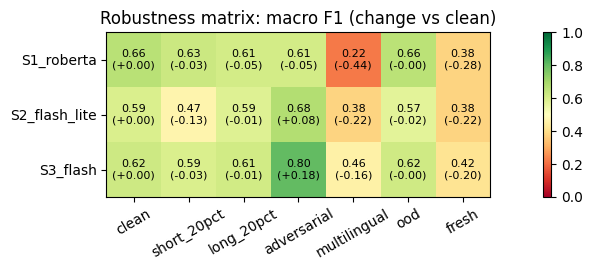

Small sets (~50) have wide CIs: treat big drops as warning signs, not proof.


In [42]:
# Chart 4: robustness heatmap — cell = macro F1, bracket = change vs clean
fig, ax = plt.subplots(figsize=(1.3 * RM.shape[1] + 2, 2.8))
im = ax.imshow(RM.values, cmap="RdYlGn", vmin=0, vmax=1)
for i in range(RM.shape[0]):
    for j in range(RM.shape[1]):
        ax.text(j, i, f"{RM.values[i, j]:.2f}\n({DELTA.values[i, j]:+.2f})", ha="center", va="center", fontsize=8)
ax.set_xticks(range(RM.shape[1]), RM.columns, rotation=30); ax.set_yticks(range(RM.shape[0]), RM.index)
ax.set_title("Robustness matrix: macro F1 (change vs clean)"); plt.colorbar(im, fraction=.02)
savefig("05_robustness_heatmap")
print("Small sets (~50) have wide CIs: treat big drops as warning signs, not proof.")

In [43]:
# Adversarial detail: did hedges/typos keep the label, and did negations flip correctly?
if "adversarial" in ROBUST_SETS:
    rows = []
    for s in MAIN:
        r = run_system(s, adv, "adversarial", verbose=False)
        ok = r.pred.values == adv.label.values
        for k in adv.kind.unique():
            rows.append({"system": s, "kind": k, "correct_share": ok[adv.kind.values == k].mean()})
    display(pd.DataFrame(rows).pivot(index="system", columns="kind", values="correct_share").round(2))

kind,hedge,negation,typo
system,,,
S1_roberta,0.88,0.50,0.59
S2_flash_lite,0.76,0.75,0.65
S3_flash,0.88,0.81,0.76


## 14. Does the proxy track the real outcome? Stance index vs actual Fed decisions (Extra #1, slide 5)
Paste the **last 8 FOMC post-meeting statements** from federalreserve.gov with each meeting's actual decision. Each system tags every sentence; the index per statement is:

`Stance = (N_hawkish − N_dovish) / N_total`

A useful system scores higher before hikes and lower before cuts. **8 points = a sanity check, not statistical proof.**

    statements | S1_roberta     run1: 64 rows (64 new)
    statements | S2_flash_lite  run1: 64 rows (64 new)
    statements | S3_flash       run1: 64 rows (64 new)


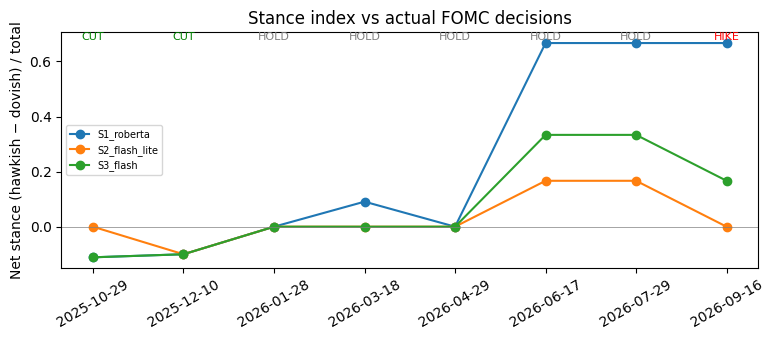

system,S1_roberta,S2_flash_lite,S3_flash,decision
date,,,,
2025-10-29,-0.111,0.000,-0.111,cut
2025-12-10,-0.100,-0.100,-0.100,cut
2026-01-28,0.000,0.000,0.000,hold
2026-03-18,0.091,0.000,0.000,hold
2026-04-29,0.000,0.000,0.000,hold
2026-06-17,0.667,0.167,0.333,hold
2026-07-29,0.667,0.167,0.333,hold
2026-09-16,0.667,0.000,0.167,hike


In [46]:
STATEMENTS = [
    {"date": "2025-10-29", "decision": "cut", "text": """Available indicators suggest that economic activity has been expanding at a moderate pace. Job gains have slowed this year, and the unemployment rate has edged up but remained low through August; more recent indicators are consistent with these developments. Inflation has moved up since earlier in the year and remains somewhat elevated. The Committee seeks to achieve maximum employment and inflation at the rate of 2 percent over the longer run. Uncertainty about the economic outlook remains elevated. The Committee is attentive to the risks to both sides of its dual mandate and judges that downside risks to employment rose in recent months. In considering additional adjustments to the target range for the federal funds rate, the Committee will carefully assess incoming data, the evolving outlook, and the balance of risks. The Committee is strongly committed to supporting maximum employment and returning inflation to its 2 percent objective. In assessing the appropriate stance of monetary policy, the Committee will continue to monitor the implications of incoming information for the economic outlook."""},
    {"date": "2025-12-10", "decision": "cut", "text": """Available indicators suggest that economic activity has been expanding at a moderate pace. Job gains have slowed this year, and the unemployment rate has edged up through September. More recent indicators are consistent with these developments. Inflation has moved up since earlier in the year and remains somewhat elevated. The Committee seeks to achieve maximum employment and inflation at the rate of 2 percent over the longer run. Uncertainty about the economic outlook remains elevated. The Committee is attentive to the risks to both sides of its dual mandate and judges that downside risks to employment rose in recent months. In considering the extent and timing of additional adjustments to the target range for the federal funds rate, the Committee will carefully assess incoming data, the evolving outlook, and the balance of risks. The Committee is strongly committed to supporting maximum employment and returning inflation to its 2 percent objective. In assessing the appropriate stance of monetary policy, the Committee will continue to monitor the implications of incoming information for the economic outlook."""},
    {"date": "2026-01-28", "decision": "hold", "text": """Available indicators suggest that economic activity has been expanding at a solid pace. Job gains have remained low, and the unemployment rate has shown some signs of stabilization. Inflation remains somewhat elevated. The Committee seeks to achieve maximum employment and inflation at the rate of 2 percent over the longer run. Uncertainty about the economic outlook remains elevated. The Committee is attentive to the risks to both sides of its dual mandate. In considering the extent and timing of additional adjustments to the target range for the federal funds rate, the Committee will carefully assess incoming data, the evolving outlook, and the balance of risks. The Committee is strongly committed to supporting maximum employment and returning inflation to its 2 percent objective. In assessing the appropriate stance of monetary policy, the Committee will continue to monitor the implications of incoming information for the economic outlook."""},
    {"date": "2026-03-18", "decision": "hold", "text": """Available indicators suggest that economic activity has been expanding at a solid pace. Job gains have remained low, and the unemployment rate has been little changed in recent months. Inflation remains somewhat elevated. The Committee seeks to achieve maximum employment and inflation at the rate of 2 percent over the longer run. Uncertainty about the economic outlook remains elevated. The implications of developments in the Middle East for the U.S. economy are uncertain. The Committee is attentive to the risks to both sides of its dual mandate. In considering the extent and timing of additional adjustments to the target range for the federal funds rate, the Committee will carefully assess incoming data, the evolving outlook, and the balance of risks. The Committee is strongly committed to supporting maximum employment and returning inflation to its 2 percent objective. In assessing the appropriate stance of monetary policy, the Committee will continue to monitor the implications of incoming information for the economic outlook. The Committee would be prepared to adjust the stance of monetary policy as appropriate if risks emerge that could impede the attainment of the Committee's goals."""},
    {"date": "2026-04-29", "decision": "hold", "text": """Recent indicators suggest that economic activity has been expanding at a solid pace. Job gains have remained low, on average, and the unemployment rate has been little changed in recent months. Inflation is elevated, in part reflecting the recent increase in global energy prices. The Committee seeks to achieve maximum employment and inflation at the rate of 2 percent over the longer run. Developments in the Middle East are contributing to a high level of uncertainty about the economic outlook. The Committee is attentive to the risks to both sides of its dual mandate. In considering the extent and timing of additional adjustments to the target range for the federal funds rate, the Committee will carefully assess incoming data, the evolving outlook, and the balance of risks."""},
    {"date": "2026-06-17", "decision": "hold", "text": """The Committee reaffirmed its policy of maintaining ample reserves in the banking system. Economic activity is expanding at a solid pace despite elevated uncertainty that owes, in part, to the conflict in the Middle East. Productivity growth and capital investment are strong. Job gains have kept pace with the workforce, and the unemployment rate has changed little. Inflation remains elevated relative to the Committee's 2 percent goal, in part reflecting supply shocks that have driven price increases in certain sectors, including energy. The Committee will deliver price stability."""},
    {"date": "2026-07-29", "decision": "hold", "text": """The Committee is continuing its policy of maintaining ample reserves in the banking system. Economic activity is expanding at a solid pace despite elevated uncertainty that owes, in part, to the conflict in the Middle East. Productivity growth and capital investment are strong. Job gains have kept pace with the workforce, and the unemployment rate has changed little. Inflation remains elevated relative to the Committee's 2 percent goal, in part reflecting supply shocks that have driven price increases in certain sectors, including energy. The Committee will deliver price stability."""},
    {"date": "2026-09-16", "decision": "hike", "text": """The Committee is continuing its policy of maintaining ample reserves in the banking system. Economic activity is expanding at a solid pace. While uncertainty remains elevated owing, in part, to geopolitical developments, domestic spending has been resilient. Productivity growth is strong, and capital investment is robust. Job gains have kept pace with the workforce, and the unemployment rate has changed little. Inflation remains elevated. The Committee will deliver price stability."""},
]
if MOCK:
    STATEMENTS = [{"date": f"2026-0{m}-15", "decision": d, "text": " ".join(MOCK_SENTENCES[:5])}
                  for m, d in zip(range(1, 9), ["hold", "hike", "hold", "cut", "cut", "hold", "hike", "hold"])]

if STATEMENTS:
    srows = []
    for st in STATEMENTS:
        for k, sent in enumerate(re.split(r"(?<=[.!?])\s+", st["text"].strip())):
            if len(sent.split()) >= 4:
                srows.append({"id": f"st_{st['date']}_{k}", "sentence": sent, "date": st["date"]})
    SENTS = pd.DataFrame(srows)
    idx_rows = []
    for s in MAIN:
        r = run_system(s, SENTS, "statements").assign(date=SENTS.date.values)
        for d, g in r.groupby("date"):
            idx_rows.append({"system": s, "date": d,
                             "stance": ((g.pred == 1).sum() - (g.pred == 0).sum()) / len(g)})
    SI = pd.DataFrame(idx_rows).pivot(index="date", columns="system", values="stance")
    DEC = pd.Series({st["date"]: st["decision"] for st in STATEMENTS})
    fig, ax = plt.subplots(figsize=(8, 3.5))
    for s in MAIN: ax.plot(SI.index, SI[s], "o-", label=s)
    for i, d in enumerate(SI.index):
        ax.annotate(DEC[d].upper(), (i, ax.get_ylim()[1]), ha="center", va="top", fontsize=8,
                    color={"hike": "red", "cut": "green"}.get(DEC[d], "grey"))
    ax.axhline(0, color="grey", lw=.5); ax.set_ylabel("Net stance (hawkish − dovish) / total")
    ax.legend(fontsize=7); plt.xticks(rotation=30); ax.set_title("Stance index vs actual FOMC decisions")
    savefig("06_stance_index")
    display(SI.assign(decision=DEC).round(3))
else:
    print("Paste statements into STATEMENTS first.")

## 15. Error analysis (20% of the grade)
- **Layer 1 — error type:** flip / missed signal / false signal / parse failure.
- **Layer 2 — language pattern:** rough keyword tags (negation, hedging, conditional, forward-looking, past description).
- **Layer 3 — root cause (✍️):** you read 10 errors per system and bucket them.

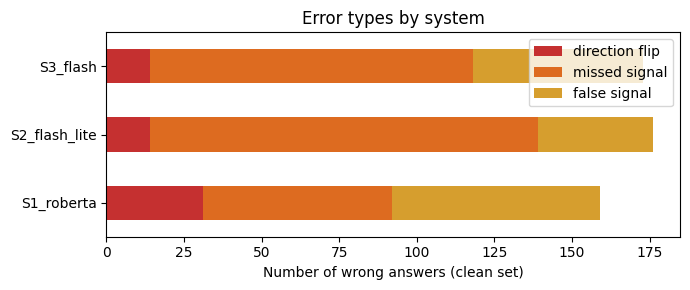

,direction flip,missed signal,false signal
S1_roberta,31,61,67
S2_flash_lite,14,125,37
S3_flash,14,104,55


In [47]:
def error_type(t, p):
    if p == -1: return "parse/API failure"
    if t == p: return "correct"
    if {t, p} == {0, 1}: return "direction flip"
    if p == 2: return "missed signal"
    return "false signal"

ET = pd.DataFrame({s: [error_type(t, p) for t, p in zip(y, PRED[s])] for s in MAIN})
counts = ET.apply(lambda c: c.value_counts()).fillna(0).drop("correct", errors="ignore").T
counts = counts[[c for c in ["direction flip", "missed signal", "false signal", "parse/API failure"] if c in counts]]
ax = counts.plot.barh(stacked=True, figsize=(7, 3), color=["#c53030", "#dd6b20", "#d69e2e", "#718096"])
ax.set_xlabel("Number of wrong answers (clean set)"); ax.set_title("Error types by system")
savefig("07_error_types")
counts

In [48]:
TAGS = {
    "negation":      r"\b(not|no|never|without)\b",
    "hedging":       r"\b(some|several|a few|many) (participants|members)\b|\b(could|might|may)\b",
    "conditional":   r"\b(if|unless)\b",
    "forward":       r"\b(will|expect\w*|anticipat\w*|outlook|going forward)\b",
    "past_describe": r"\b(was|were|had|declined|rose|fell|increased|decreased)\b",
}
tag_df = pd.DataFrame({t: test.sentence.str.contains(rx, case=False, regex=True) for t, rx in TAGS.items()})
rows = []
for t in TAGS:
    m = tag_df[t].values
    rows.append({"tag": t, "n": m.sum(), **{s: 1 - np.mean(PRED[s][m] == y[m]) for s in MAIN}})
print("Error rate per language pattern (keyword tags are rough; say so)")
pd.DataFrame(rows).set_index("tag").round(3)

Error rate per language pattern (keyword tags are rough; say so)


,n,S1_roberta,S2_flash_lite,S3_flash
tag,,,,
negation,61,0.377,0.311,0.344
hedging,70,0.414,0.314,0.329
conditional,21,0.333,0.571,0.524
forward,142,0.324,0.415,0.408
past_describe,154,0.390,0.403,0.403


In [50]:
# Layer 3: export 10 errors per system for you to bucket by hand.
BUCKETS = "model wrong | gold disputable | not policy text | genuinely ambiguous"
path = f"{SHEETS}/error_buckets.csv"
if not os.path.exists(path):
    err_rows = []
    for s in MAIN:
        wrong = np.where(PRED[s] != y)[0]
        pick = np.random.default_rng(SEED).choice(wrong, min(10, len(wrong)), replace=False)
        for i in pick:
            err_rows.append({"system": s, "id": test.id[i], "sentence": test.sentence[i],
                             "gold": LABELS[y[i]], "pred": LABELS[PRED[s][i]] if PRED[s][i] >= 0 else "FAIL",
                             "bucket": ""})
    pd.DataFrame(err_rows).to_csv(path, index=False)
    print(f"exported {path}. Fill 'bucket' with one of: {BUCKETS}")
eb = pd.read_csv(path)
if MOCK: eb["bucket"] = np.random.default_rng(SEED).choice(BUCKETS.split(" | "), len(eb))
if eb.bucket.notna().all():
    display(pd.crosstab(eb.system, eb.bucket))

bucket,genuinely ambiguous,gold disputable,model wrong,not policy text
system,,,,
S1_roberta,0,4,3,3
S2_flash_lite,3,6,1,0
S3_flash,1,5,3,1


**What the errors tell us**
- **Error type (clean set, 496):** S1 makes the fewest errors (159 vs 173 for S3 and 176 for S2), but twice as many direction flips (31 vs 14). Gemini's errors are mostly *missed signals*: it answers "neutral" when gold gives a stance.
- **Language patterns:** Gemini struggles with conditional sentences ("if", "unless"; 52–57% wrong vs 33% for S1). S1 struggles most with hedged sentences (41% wrong). Keyword tags are rough and some groups are small (n = 21).
- **Root cause (30 errors read by hand):** half (15/30) are *gold disputable*: sentences that describe the economy without a clear policy stance, where the model's "neutral" looks reasonable. Only 7/30 are clearly the model's fault.
- **Link to Section 12:** my own labels agreed with gold only 58% of the time. Together this suggests part of the "error" is label convention, not model weakness. S1 learned the convention from training data; Gemini reads more like a human.
- **Caveat:** 10 errors per system, one rater. Warning signs, not proof.

## 16. Apply the pre-registered decision rule
The notebook applies section 1's rule mechanically, so the recommendation is not a judgement call.

In [51]:
best_cascade = CASC.loc[CASC.macro_f1.idxmax()]
cands = {s: {"macro_f1": TABLE.macro_f1[s], "p95_s": TABLE.p95_s[s], "usd_per_1000": TABLE.usd_per_1000[s],
             "pred": PRED[s]} for s in MAIN}
cands[f"cascade_t{best_cascade.threshold}"] = {"macro_f1": best_cascade.macro_f1, "p95_s": best_cascade.p95_s,
                                               "usd_per_1000": best_cascade.usd_per_1000, "pred": best_cascade.pred}
best = max(cands, key=lambda k: cands[k]["macro_f1"])
def flip_not_worse(k):
    d = np.array([flip_mask(y[i], cands[k]["pred"][i]).mean() - flip_mask(y[i], cands[best]["pred"][i]).mean()
                  for i in BOOT_IDX[:1000]])
    return np.percentile(d, 2.5) <= 0
rows = []
for k, c in cands.items():
    a = c["macro_f1"] >= cands[best]["macro_f1"] - 0.02
    b = c["p95_s"] < 1.0
    f = flip_not_worse(k)
    rows.append({"candidate": k, "macro_f1": c["macro_f1"], "p95_s": c["p95_s"], "usd_per_1000": c["usd_per_1000"],
                 "(a) F1 within 2pt": a, "(b) p95 < 1s": b, "(c) flips not worse": f, "qualifies": a and b and f})
RULE = pd.DataFrame(rows).set_index("candidate")
ok = RULE[RULE.qualifies]
DEPLOY = ok.usd_per_1000.idxmin() if len(ok) else best
print(DECISION_RULE); display(RULE.round(4))
print(f">>> RECOMMENDATION: deploy {DEPLOY}")


Decision rule (fixed on 2026-09-30, before any results):
Deploy the CHEAPEST system (S1, S2, S3 or the S1->S3 cascade) that
  (a) has macro F1 within 2 points of the best system,
  (b) has p95 latency under 1 second per sentence, and
  (c) has a direction-flip rate not significantly worse than the best system
      (paired bootstrap 95% CI of the difference includes 0 or favours it).
If none qualifies, deploy the system with the highest macro F1.



,macro_f1,p95_s,usd_per_1000,(a) F1 within 2pt,(b) p95 < 1s,(c) flips not worse,qualifies
candidate,,,,,,,
S1_roberta,0.6604,0.0116,0.0000,True,True,False,False
S2_flash_lite,0.5946,0.9611,0.0390,False,True,True,False
S3_flash,0.6215,1.9751,0.1908,False,False,True,False
cascade_t0.9,0.6759,1.7406,0.1114,True,False,True,False


>>> RECOMMENDATION: deploy cascade_t0.9


In [52]:
# Export the result table (slide 41 REQUIRED) as CSV + markdown for the slides/write-up.
cols = ["macro_f1", "f1_ci_low", "f1_ci_high", "weighted_f1", "accuracy", "hawk_recall", "flip_rate",
        "parse_fail_rate", "p50_s", "p95_s", "p99_s", "throughput_per_s", "tokens_per_req",
        "usd_per_1000", "biz_cost_per_1000"]
TABLE[cols].round(4).to_csv(f"{BASE}/result_table.csv")
PAIRS.round(4).to_csv(f"{BASE}/pairwise_tests.csv", index=False)
RM.round(3).to_csv(f"{BASE}/robustness_matrix.csv")
print(TABLE[cols].round(3).to_markdown())
print("\nFigures saved in", FIGS, ":", sorted(os.listdir(FIGS)))

| system        |   macro_f1 |   f1_ci_low |   f1_ci_high |   weighted_f1 |   accuracy |   hawk_recall |   flip_rate |   parse_fail_rate |   p50_s |   p95_s |   p99_s |   throughput_per_s |   tokens_per_req |   usd_per_1000 |   biz_cost_per_1000 |
|:--------------|-----------:|------------:|-------------:|--------------:|-----------:|--------------:|------------:|------------------:|--------:|--------:|--------:|-------------------:|-----------------:|---------------:|--------------------:|
| B1_majority   |      0.222 |       0.207 |        0.234 |         0.331 |      0.498 |         0     |       0     |                 0 |   0     |   0     |   0     |          89039.6   |            0     |          0     |             502.016 |
| B2_random     |      0.315 |       0.275 |        0.356 |         0.342 |      0.329 |         0.307 |       0.194 |                 0 |   0     |   0     |   0     |          52350.4   |            0     |          0     |            1445.57  |
| S1_rob

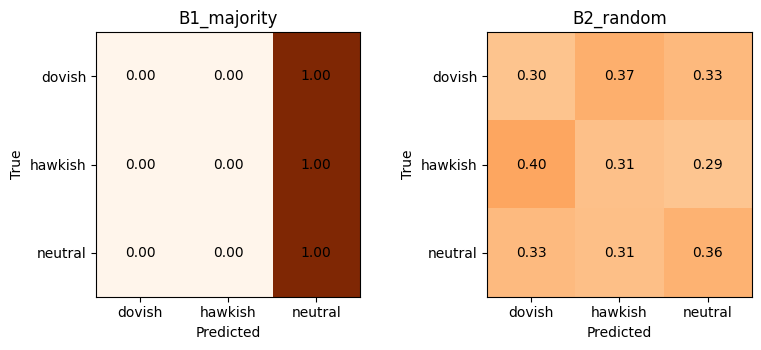

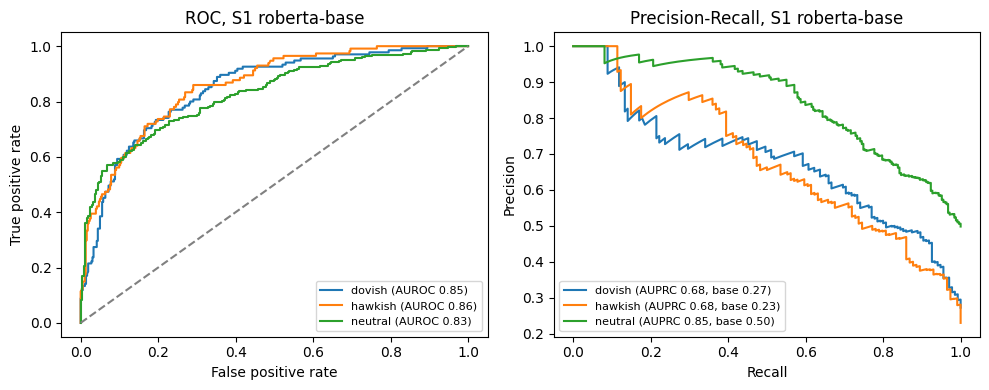

A random model's AUPRC equals the class prevalence, so compare AUPRC to 'base'.


,prevalence,AUROC,AUPRC
class,,,
dovish,0.272,0.845,0.681
hawkish,0.230,0.857,0.680
neutral,0.498,0.826,0.845


In [54]:
# Slides 11, 16-17: baseline confusion matrices + AUROC / AUPRC for RoBERTa (one class vs rest)
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
for ax, s in zip(axes, ["B1_majority", "B2_random"]):
    cm = confusion_matrix(y, PRED[s], labels=[0, 1, 2], normalize="true")
    ax.imshow(cm, cmap="Oranges", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center")
    ax.set_xticks(range(3), LABELS); ax.set_yticks(range(3), LABELS)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(s)
savefig("02b_baseline_confusion")

P1 = np.array([json.loads(x) for x in RES["S1_roberta"].probs])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))
rows = []
for k, name in enumerate(LABELS):
    yk = (y == k).astype(int)
    fpr, tpr, _ = roc_curve(yk, P1[:, k]); pr, rc, _ = precision_recall_curve(yk, P1[:, k])
    auroc, auprc = roc_auc_score(yk, P1[:, k]), average_precision_score(yk, P1[:, k])
    a1.plot(fpr, tpr, label=f"{name} (AUROC {auroc:.2f})")
    a2.plot(rc, pr, label=f"{name} (AUPRC {auprc:.2f}, base {yk.mean():.2f})")
    rows.append({"class": name, "prevalence": yk.mean(), "AUROC": auroc, "AUPRC": auprc})
a1.plot([0, 1], [0, 1], "--", color="grey"); a1.set_xlabel("False positive rate"); a1.set_ylabel("True positive rate")
a2.set_xlabel("Recall"); a2.set_ylabel("Precision")
a1.set_title("ROC, S1 roberta-base"); a2.set_title("Precision-Recall, S1 roberta-base")
a1.legend(fontsize=8); a2.legend(fontsize=8)
savefig("02c_roc_pr_roberta")
print("A random model's AUPRC equals the class prevalence, so compare AUPRC to 'base'.")
pd.DataFrame(rows).set_index("class").round(3)

**Conclusion**
- **Rule outcome:** no system met all three pre-registered conditions, so the fallback applies: deploy the highest macro F1, the S1→S3 cascade at t = 0.9 (macro F1 0.676).
- **Caveat 1:** the threshold 0.9 was chosen by looking at test results, so 0.676 is optimistic. It should be re-selected on a validation split.
- **Caveat 2:** the cascade misses the latency target (p95 1.74 s vs < 1 s). Only S1 alone meets it.
- **Accuracy vs business cost disagree:** S1 has the best macro F1 but the highest business cost among the real systems (570 per 1,000 at flip cost 5), because it makes twice as many hawkish↔dovish flips. S3 has the lowest cost at every flip weight tested.
- **Statistics:** no pairwise difference survives Holm correction on this test set (n = 496).
- **Labels:** my own labels agreed with gold only 58% of the time, and half of the errors I read were "gold disputable". Part of the gap between systems is label convention, not model quality.
- **Bottom line:** if flips are costly, S3 or the cascade. If only macro F1 matters, S1. The choice depends on the business cost of a wrong-way call more than on the model.